# Lesson 16. How many cameras does one splat need?

[Course plan](../../README.md)

Two orange splats look identical in a first photograph. One is small and close, the other larger and farther away. Both produce essentially zero image error. The camera moves sideways and one splat slips off the target. That shift gives the optimizer information about depth.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
course_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'splat_render.py').is_file())
if str(course_root) not in sys.path:
    sys.path.insert(0, str(course_root))
import numpy as np
from IPython.display import display
import matplotlib.pyplot as plt
import splat_render as sr
import splat_demos as demo
lang = "en"

## Two training frames and a third for checking

The left frame comes from a fixed target at depth 4, the right from the current scene. Camera positions are known in advance. Camera A sits at X = 0, B at +0.8, and the check camera at −0.6. Their axes remain parallel. The training selector chooses the images that enter the loss. The preview camera only changes the image on screen.

The model starts at depth 2.4. In camera A both images match before a single update. B sees a clear mismatch. After twenty steps on both frames, the third view improves as well, even though none of its pixels took part in the update.

In [2]:
display(demo.experiment(16, "en"))

## Two ways to make the same orange mark

With only the first shutter open there is an orange middle and a gradual transition to white. The photograph describes the location of the middle **on the screen**. The transition also tells us something about width **in pixels**. What is the distance in centimeters from lens to object? A small orange ball up close can cover the same part of the field of view as a larger ball farther away. The photograph alone does not supply that distance.

For this experiment one world unit stands for one meter. Depth increases forward from camera A. Pixel centers are numbered from zero, so the end columns of a 33-pixel image are 0 and 32 and its center is exactly 16. Columns increase to the right, rows downward. A projected center at 18.8 makes sense. The renderer samples the weights at integer positions on either side. Rounding the center to 19 before evaluating the weights would make slow motion look like a sequence of jumps.

The same photograph will get two possible captions. One says “2.4 m” and the other says “4 m.” Color, orientation, background, and opacity stay fixed. Switching **between cameras** and sliding **the model along the ray** are separate experiments. We first keep A still and compare the two captions. Only then do we move the camera to the right, leaving each candidate object's parameters intact. Camera B gets two different predictions before training has even begun.

## A family of identical first frames

The unknown depth $z>0$ is measured in world units. The model center is $(0.10z,-0.05z,z)$ and its three scales are $(0.12z,0.08z,0.06z)$. We deliberately tie six values to a single parameter. Doubling $z$ doubles the distance and the size together. Color $(0.85,0.20,0.08)$ and opacity $0.9$ stay fixed. Camera A faces $+Z$, has focal length $f=28$ pixels, and puts the center of the $33\times33$ frame at $(16,16)$.

The horizontal coordinate is $u_A=16+28\cdot0.10z/z=18.8$; the vertical coordinate is $v_A=16+28\cdot(-0.05)z/z=14.6$. The two factors of $z$ cancel in each ratio. Horizontal scale likewise contains $0.12z/z$. The footprint correction for depth extent also survives this cancellation: every entry of the Jacobian scales as $1/z$, while spatial covariance grows as $z^2$. In $J\Sigma J^\mathsf{T}$ the two divisions by $z$ cancel that square. The **whole footprint** matches, including its falloff at the edges.

At $z=2.4$, center $X=0.24$ and horizontal scale is $0.288$. At $z=4$ they are $0.40$ and $0.48$. No amount of optimization on camera A can distinguish the two scenes.

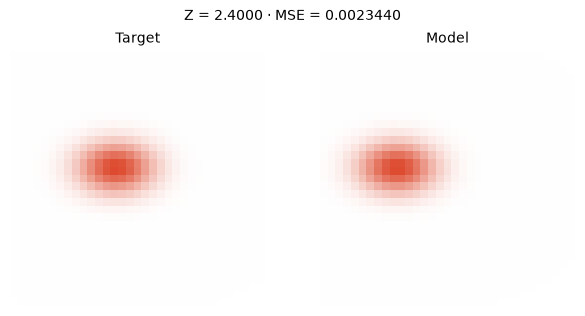

In [3]:
fig = demo.ray_figure("en")
display(fig)
plt.close(fig)

### Where did the width go?

Matching centers still leaves a loophole. Could one footprint be narrower, allowing its edge colors to give the game away? Along the horizontal axis one scale of the near candidate covers $28\cdot0.288/2.4=3.36$ pixels. For the far one it covers $28\cdot0.48/4=3.36$ pixels. There is also an axis extending in depth. The center sits a little to the right of the optical axis, so moving forward along depth shifts the footprint slightly left. The magnitude of its contribution to horizontal scale is $28\cdot0.10\cdot0.06=0.168$ pixels in both cases. The sign matters for the motion of a **point**. Independent contributions to spread along the horizontal direction are squared. The result is $3.36^2+0.168^2=11.317824$ square pixels for either object.

Why does the program bother calculating different 3D centers and world-space matrices? The photograph records a finished image. The model also has to answer a question about a different observer position. Its numbers already differ, but this camera combines them in a way that cancels the difference. A fit supplied with just this image can stop anywhere along a flat stretch of loss. Longer training adds no observations.

In [4]:
for z in (2.4, 4.0):
    item = sr.project_splats(sr.ray_scene(z), sr.translated_camera(0), 33, 33)[0]
    print(f"z = {z:.1f}   u = {item['mean'][0]:.2f}   Sxx = {item['covariance'][0,0]:.6f}")
    np.testing.assert_allclose(item["covariance"][0, 0], 3.36**2 + .168**2)

z = 2.4   u = 18.80   Sxx = 11.317824
z = 4.0   u = 18.80   Sxx = 11.317824


## Parallax before optimization

After camera B moves right by $b=0.8$, it sees the point at camera coordinate $X-b$. Substitution into perspective gives

$$
u_B=16+28(0.10z-b)/z=18.8-28b/z.
$$

The nearer model gives $u_B=18.8-22.4/2.4\approx9.467$, while the target gives $18.8-22.4/4=13.2$. The shift between the views is called parallax. For the target, $u_A-u_B=5.6$ pixels. Starting from $u_A-u_B=fb/z$, known $f,b$ and matching centers give depth $z=28\cdot0.8/5.6=4$. In photographs we would first have to find pixels corresponding to the same point. A Gaussian does not even have a hard edge. In the experiment we compare all the pixels of the two frames.

In [5]:
for z in [2.4, 4.0, 7.0]:
    model = sr.ray_scene(z)
    for baseline in (0, .8, -.6):
        cam = sr.translated_camera(baseline)
        uv = sr.project_splats(model, cam, 33, 33)[0]["mean"]
        print(f"Z={z:g}, Xcam={baseline:+g}: u={uv[0]:.3f}, MSE={sr.ray_loss(z,(baseline,)):.8f}")

Z=2.4, Xcam=+0: u=18.800, MSE=0.00000000
Z=2.4, Xcam=+0.8: u=9.467, MSE=0.00468808
Z=2.4, Xcam=-0.6: u=25.800, MSE=0.00277686
Z=4, Xcam=+0: u=18.800, MSE=0.00000000
Z=4, Xcam=+0.8: u=13.200, MSE=0.00000000
Z=4, Xcam=-0.6: u=23.000, MSE=0.00000000
Z=7, Xcam=+0: u=18.800, MSE=0.00000000
Z=7, Xcam=+0.8: u=15.600, MSE=0.00211890
Z=7, Xcam=-0.6: u=21.200, MSE=0.00121875


### Half a pixel of measurement error

Suppose the true center fell between columns and matching the two images introduced half a pixel of error in their difference. At our baseline the true disparity is 5.6. Adding half a pixel gives $22.4/6.1\approx3.67$ m. Subtracting it gives $22.4/5.1\approx4.39$ m. This brackets the actual four-meter depth. The interval is asymmetric. A fixed change in the denominator has a larger effect when that denominator is small.

With the cameras just eight centimeters apart, $fb=28\cdot0.08=2.24$, and the same object gives only $2.24/4=0.56$ pixels of disparity. The measurement error is unchanged. Now the lower end of the measured disparity range is barely above zero. One estimate is about 2.11 m and the other is already 37.33 m. The arithmetic is sound in both cases. This is what a shortage of geometric information in the input looks like.

A large baseline has its own cost. When an object is seen from very different sides, some details are hidden and cease to be shared marks. Choosing an evaluation image involves more than its angle. Is the feature in the frame? Do we know the camera pose and focal length? Are the observations different enough to produce visibly different predictions under competing hypotheses? Here all three poses are known before fitting and the single splat stays visible.

In [6]:
for baseline in (.8, .08):
    disparity = 28*baseline/4
    estimates = [28*baseline/(disparity+e) for e in (-.5, 0, .5)]
    print(f"b = {baseline:.2f} m, d = {disparity:.2f} px   z =", np.round(estimates, 3))

b = 0.80 m, d = 5.60 px   z = [4.392 4.    3.672]
b = 0.08 m, d = 0.56 px   z = [37.333  4.     2.113]


## One actual update from image error

Each camera has its own mean squared RGB difference from lesson 6, $L_A$ or $L_B$. For a single view the denominator counts $33\cdot33\cdot3=3267$ values. Initially $L_A$ is zero to numerical precision and $L_B\approx0.00468808$. With equal weight for the cameras, $L=(L_A+L_B)/2\approx0.00234404$. The held-out view never enters this sum.

There is a single unknown $z$. To check the derivative, we render two neighboring cases, $z-h$ and $z+h$, with $h=0.002$ world units. The denominator of the slope is the distance between these cases, $2h=0.004$.

$$
\begin{aligned}
g &\approx \frac{L(2.402)-L(2.398)}{0.004}\\
  &\approx (0.0023357144-0.0023523820)/0.004=-0.004167.
\end{aligned}
$$

The minus sign says that increasing depth a little decreases the loss here. With a learning rate of $\eta=80$ we get $z_{\rm new}=2.4-80(-0.004167)\approx2.73335$. The rate converts slope into a change in depth; the value 80 belongs to this particular loss scale. Depth stays within 1.25 to 7 to keep the model in front of the camera. After twenty updates $z\approx3.8101$. The held-out error falls from $0.00277686$ to $0.00001703$. Training on A alone leaves the loss curve essentially flat.

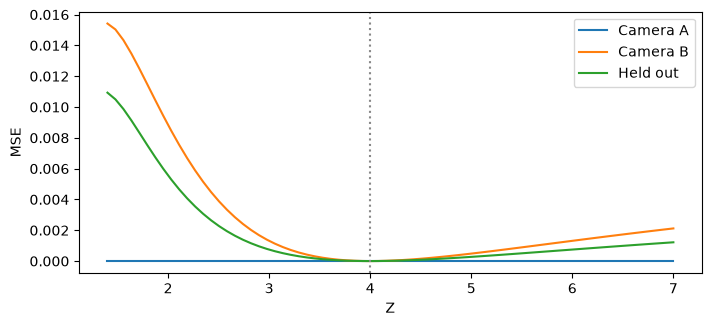

In [7]:
fig = demo.ray_landscape("en")
display(fig)
plt.close(fig)

In [8]:
z = 2.4
for step in range(20):
    z, gradient = sr.depth_step(z, (0,.8))
print(round(z, 6), sr.ray_loss(z, (0,.8)), sr.ray_loss(z, (-.6,)))
assert sr.ray_loss(z, (-.6,)) < sr.ray_loss(2.4, (-.6,))

3.810089 1.5238536519958356e-05 1.70260316191234e-05


## How a single pixel votes

So far the slope of the loss has appeared as one number from two nearby renders. We can look inside that number. Camera B, row 15, column 14. The target has an orange center there while the closer model shows a lighter edge. Blue is a revealing channel since it drops sharply on the way from white to orange. The model gives $I=0.66766$, the target $Y=0.20773$. Both range from zero to one. The residual is $r=I-Y=+0.45993$. The plus sign means excess blue. Its square adds about $0.21154$ to the image sum before division by the number of samples.

Depth increases slightly. The model center shifts right, and a denser part of the footprint moves over our pixel. Renders at 2.398 and 2.402 m measure the change in intensity. Blue would fall by about $0.50675$ per meter **if** the local slope persisted that far. The measurement itself spans just four millimeters. The slope times a small depth displacement gives the intensity change. Another multiplication by $2r$ gives the change in squared error. The 2 comes from expanding $(r+\delta)^2-r^2=2r\delta+\delta^2$. After division by a small $\delta$, the second term goes to zero.

$$
\begin{aligned}
g_{\rm pixel}&=\frac{2(I-Y)}{3267}\frac{\Delta I}{\Delta z}\\
&\approx\frac{2\cdot0.45993}{3267}\cdot(-0.50675)
\approx-0.00014268.
\end{aligned}
$$

This is the vote of one channel at one pixel in the derivative of B's mean error with respect to depth. Neighboring pixels can vote the other way. Blue at column 10 of the same row is already too dark. More darkening there makes the match worse, producing a positive contribution of about $+0.00002545$. The map below adds the three **signed** votes at each location. Faraway white background says almost nothing about depth. Strong votes appear where sliding the silhouette changes the color. Adding up camera B gives about $-0.008334$. Averaging across the two training cameras recovers $-0.004167$ because A contributes zero along this family of models.

The code includes another check. The same frame is rendered from tensors. The chain from depth to every color stays inside PyTorch, including the change of scale and the projection. A backward pass combines contributions from all the channels using differentiation rules. These independent calculations measure the same slope. Their last digits can differ because the first one uses a finite step.

B[15,14,blue]: -0.00014268   B total: -0.00833378
PyTorch: -0.0083338


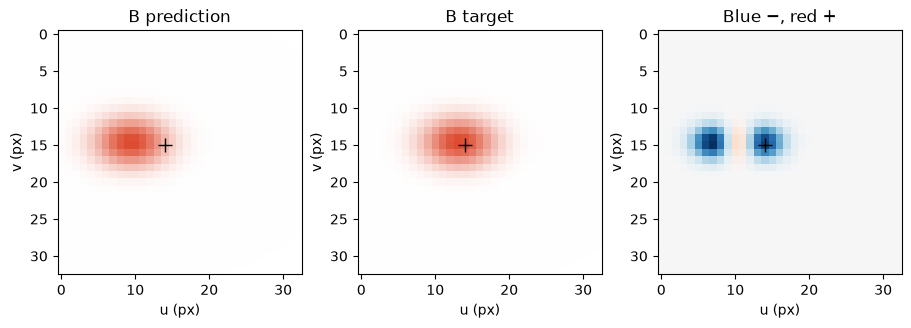

In [9]:
from splat_fit import render_parallel
import torch

cam_b = sr.translated_camera(.8)
def frame_at(z):
    return sr.render_scene(sr.ray_scene(z), cam_b, 33, 33)

prediction, target = frame_at(2.4), frame_at(4)
h = .002
slope = (frame_at(2.4+h)-frame_at(2.4-h))/(2*h)
votes = 2*(prediction-target)*slope/prediction.size
print("B[15,14,blue]:", round(votes[15,14,2], 8), "  B total:", round(votes.sum(), 8))

z = torch.tensor(2.4, dtype=torch.float64, requires_grad=True)
centers = z*z.new_tensor([[.10,-.05,1.]])
scales = z*z.new_tensor([[.12,.08,.06]])
tensor_frame = render_parallel(centers, scales, z.new_tensor([[.85,.2,.08]]),
                               z.new_tensor([.9]), .8)
(tensor_frame-torch.as_tensor(target)).square().mean().backward()
print("PyTorch:", round(z.grad.item(), 8))
np.testing.assert_allclose(votes.sum(), z.grad.item(), rtol=2e-5)

fig, axes = plt.subplots(1, 3, figsize=(9, 3.2), constrained_layout=True)
axes[0].imshow(prediction); axes[1].imshow(target)
signed = votes.sum(axis=2)
limit = np.abs(signed).max()
axes[2].imshow(signed, cmap="RdBu_r", vmin=-limit, vmax=limit)
titles = (["Модель B", "Образец B", "Синий −, красный +"] if lang=="ru"
          else ["B prediction", "B target", "Blue −, red +"])
for ax, title in zip(axes, titles):
    ax.set_title(title); ax.set_xlabel("u (px)"); ax.set_ylabel("v (px)")
    ax.plot(14,15,"+",color="black",ms=10)
plt.show()

## From one parameter to a scene with two Gaussians

Now we untie position from width. In a separate experiment two splats have independent centers and RGB values, six numbers each. Their scales, rotations, opacities, and camera calibration are known. Two color images come from cameras at $X=-0.8$ and $+0.65$. A third camera at $+0.12$ supplies a check view. All three panels below use that camera.

The program computes footprints, blends them and averages errors over **only the first two** frames. In PyTorch a computation graph connects color and center to every rendered pixel. Calling `backward()` gives each of the 12 numbers the rate of change of the shared loss, as in lesson 8. Adam chooses the steps here. It keeps running estimates of each parameter's gradient and squared gradient to adjust the size of its update. The sorted layer indices stay fixed within a step; an order swap itself is discrete. After an update RGB stays within zero to one and depth within 1.25 to 7.

Training starts with inaccurate centers and muted colors. Across 45 steps the held-out MSE drops from about $0.002427$ to $0.00000827$. Low error on another image checks the prediction at that particular view. Hidden details and unobserved sides still have no measurements.

In [10]:
import torch
from splat_fit import train_two_splats
torch.set_num_threads(1)
run = train_two_splats(45)
print(np.array(run["history"])[[0, 15, 45]])
assert run["history"][-1][1] < run["history"][0][1] / 100

[[2.35787013e-03 2.42663412e-03]
 [1.26140177e-04 1.16656163e-04]
 [9.42653280e-06 8.26944021e-06]]


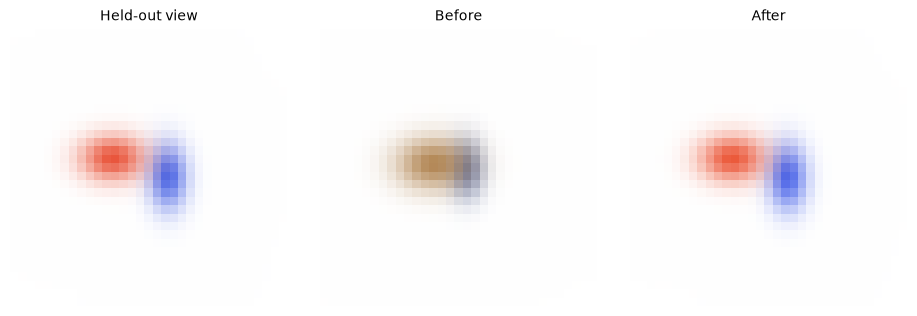

In [11]:
fig = demo.panel([run["target"],run["before"],run["after"]], ["Held-out view","Before","After"])
display(fig)
plt.close(fig)

### What changed in the second fit?

The pair of splats now has twelve controls in place of one. Each center has three numbers in meters. Each color has three unitless fractions. An identical numerical gradient for color and depth would describe different changes. The optimizer receives a separate array for each kind and keeps an update history for each element. The observations have a shape too. Two frames with 33 rows, 33 columns and three channels contain $2\cdot33\cdot33\cdot3=6534$ numbers. This need not amount to 6534 independent geometric equations. Thousands of neighboring values may describe the same white background.

The first fit had no choice between altering color and altering coverage. The second one does. A model painting excess color on a patch of white can reduce error by moving that patch back toward the object. It could also move its color closer to white. Then it would match the background better but leave a pale patch inside the silhouette. Other pixels and the second camera carry that cost into the objective. There are two clues in the “Before” image. A displaced contour points toward geometry. An error that remains where the contours already agree can also come from color or opacity.

Here we synthesized all three images and therefore know the answer. With photographs, true 3D centers are unavailable. A reserved camera gives a way to evaluate the prediction. If its score were used after every update to choose the best settings, it would participate in that choice. An independent final assessment would then need another photograph. Our step count was fixed in advance and the held-out curve is merely recorded. The next experiment introduces a different reason why error might persist. Even with accurate cameras and perfectly clean backgrounds, one splat may have too few peaks to represent two separate details.

## Experiments and worked answers

Would a second photograph from precisely the same position help once the first view matches? How distinguishable are the depths with a very small baseline?

<details><summary>Worked answer</summary>

A duplicate of A doubles the number of measurements and the denominator of the average, leaving the same flat dependence on depth. With $b=0.008$ instead of $0.8$, the center discrepancy between the 2.4 and 4 hypotheses is only $3.733/100\approx0.037$ pixels. A difference still exists in theory. In photographs it is easier to lose to noise, blur, and pose error.

</details>

### A larger canvas

A white border is added to both images with the original pixels and projections left intact. There are now twice as many color samples. Prediction and target agree throughout the added region. What happens to MSE and to the first depth update with the same learning rate?

<details><summary>The border calculation</summary>

The numerator gains a sum of zeros. The denominator doubles, so the loss and its derivative halve. At the old rate of 80 the depth displacement is about $0.33335/2=0.16668$ m. The original patch still contains the same geometric information. The normalization that translates it into an update length has changed. The added values must agree at neighboring depth settings too, or the border's contribution to the derivative must be included.

</details>

### The camera is on the wrong side

The mark has $u_A=18.8$ and $u_B=13.2$. A camera file lists $b=-0.8$ m. What depth comes out of the two marks? How does it fit the requirement $z>0$?

<details><summary>Checking the sign of the baseline</summary>

The difference is $18.8-13.2=+5.6$ pixels. The numerator is $28(-0.8)=-22.4$, giving $-22.4/5.6=-4$ m. Our camera looks forward along positive Z. A positive depth cannot match both marks with that sign for the baseline. Checking the translation direction and the order of image subtraction comes before adjusting the learning rate. Exchanging both cameras would flip the signs of both the baseline and the disparity, preserving the original result.

</details>

### Whose gradient is it?

One camera gives a depth slope of $+0.002$, the other $-0.008$. The images have equal size and the cameras have equal weights. Where does depth move at a learning rate of 10? What if the second camera accidentally gets weight zero?

<details><summary>Combining two votes</summary>

Equal weights give $(0.002-0.008)/2=-0.003$. Descent subtracts the slope, increasing depth by $0.03$ m. If the mean is taken only over the first camera, its slope is $+0.002$ and depth falls by $0.02$ m. Two views can disagree on the direction to move. The sign of each contribution depends on what happens to that particular image as the candidate model shifts.

</details>